In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

In [3]:
train=pd.read_csv("../data/raw/Train.csv")
test=pd.read_csv("../data/raw/Test.csv")

In [4]:
train["time"]=pd.to_datetime(train["time"])
test["time"]=pd.to_datetime(test["time"])

In [ ]:
train["month"]=train["time"].dt.month
test["month"]=test["time"].dt.month

In [ ]:
train["month_sin"]=np.sin(2 * np.pi * train["month"]/12)
train["month_cos"]=np.cos(2 * np.pi * train["month"]/12)

test["month_sin"]=np.sin(2* np.pi * test["month"]/12)
test["monrh_cos"]=np.cos(2 * np.pi *test["month"]/12)


In [19]:
X=train.drop(columns=["sample_id","target","time"])
y=train["target"]

In [20]:
print(X.columns)

Index(['lat', 'lon', 'TWS_t', 'SPEI_01_t', 'SPEI_03_t', 'SPEI_06_t',
       'SPEI_12_t', 'SOIL_MOISTURE_t', 'month_sin', 'month_cos', 'month'],
      dtype='str')


In [21]:
X_train,X_valid,y_train,y_valid=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [22]:
model=HistGradientBoostingRegressor(random_state=42)
model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [23]:
predictions = model.predict(X_valid)

In [24]:
from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(y_valid, predictions)

print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 0.5129


In [ ]:
from sklearn.inspection import permutation_importance


In [26]:
result=permutation_importance(
    model,
    X_valid,
    y_valid,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error"
)

In [27]:
importance=pd.DataFrame({
    "Feature":X.columns,
    "Importance":result.importances_mean
})

In [28]:
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

In [29]:
print(importance)

            Feature  Importance
2             TWS_t    0.569598
0               lat    0.020441
1               lon    0.017098
5         SPEI_06_t    0.015142
4         SPEI_03_t    0.004654
9         month_cos    0.004646
6         SPEI_12_t    0.004406
8         month_sin    0.003245
10            month    0.003093
7   SOIL_MOISTURE_t    0.000887
3         SPEI_01_t    0.000561


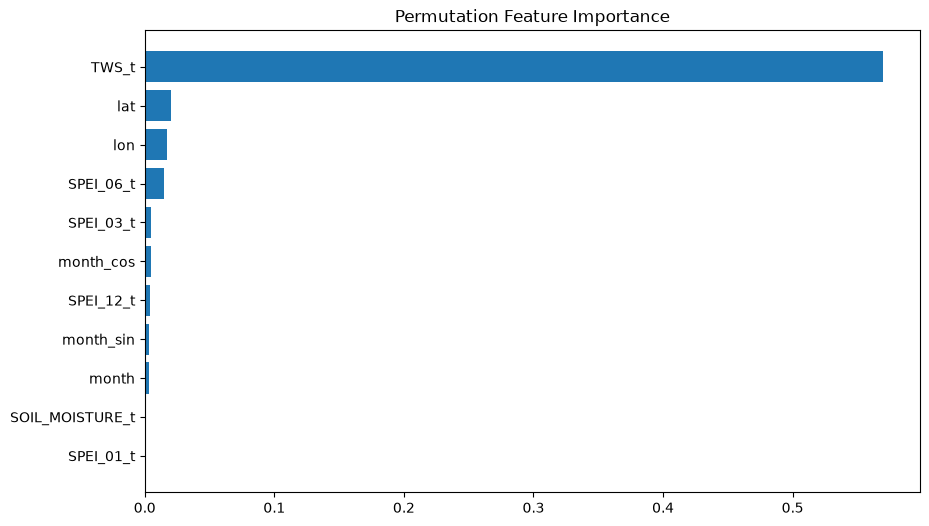

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Permutation Feature Importance")

plt.show()

In [35]:
features = [
    "lat",
    "lon",
    "TWS_t",
    "SPEI_03_t",
    "SPEI_06_t",
    "SPEI_12_t"
]

X = train[features]
y = train["target"]

In [36]:
X_train,X_valid,y_train,y_valid=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [37]:
model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [38]:
predictions = model.predict(X_valid)

In [39]:
rmse=root_mean_squared_error(y_valid,predictions)
print(rmse)

0.5179607764710391
